# 72 — Visual goal-conditioned policies and VLA intuition

This robot-learning practice studies one central idea: **the correct action depends on both what the agent sees and what it is asked to do**. We first use a goal image, then replace the goal channel with a language instruction. The models are intentionally small; the aim is intuition rather than reproducing a large robotics system.

Companion note: [Visual goal-conditioned policies and VLA intuition](../notes/17-robot-learning/visual-goal-conditioned-policies-and-vla.md).

In [2]:
from collections import deque
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

SEED = 7
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using {DEVICE}")

Using mps


## 1. A small visual navigation world

The agent moves on a $6\times6$ grid. Channel 0 marks obstacles, channel 1 marks the agent, and channel 2 marks the requested goal. Changing only the goal channel can change the correct action.

In [3]:
GRID_SIZE = 6
OBSTACLES = {(1, 2), (2, 2), (3, 2), (4, 4)}
GOAL_STATES = ((0, 0), (0, 5), (5, 5))
GOAL_NAMES = ("top left", "top right", "bottom right")
ACTION_DELTAS = ((-1, 0), (0, 1), (1, 0), (0, -1))
ACTION_NAMES = ("up", "right", "down", "left")

def transition(state, action):
    row, column = state
    d_row, d_column = ACTION_DELTAS[action]
    candidate = (row + d_row, column + d_column)
    if (0 <= candidate[0] < GRID_SIZE and 0 <= candidate[1] < GRID_SIZE
            and candidate not in OBSTACLES):
        return candidate
    return state

### Exercise 1 — Render a goal-conditioned observation

Fill the three channels at the obstacle, agent, and goal locations.

Each observation has shape `(3, 6, 6)`, following PyTorch's channel-first image convention `(channels, height, width)`. The grid has six rows and six columns, while its three channels store different kinds of information:

- channel 0 is a $6\times6$ obstacle map: obstacle cells are 1 and other cells are 0;
- channel 1 is a $6\times6$ agent map: only the agent's current cell is 1;
- channel 2 is a $6\times6$ goal map: only the requested goal cell is 1.

The channels are similar to separate red, green, and blue image channels, except that here they have explicit semantic meanings. Stacking many observations later produces shape `(N, 3, 6, 6)`, where `N` is the number of examples.

Matplotlib expects image channels last, with shape `(height, width, channels)`. Therefore, `observation.transpose(1, 2, 0)` changes `(3, 6, 6)` into `(6, 6, 3)` for visualization; it does not change the underlying grid information.

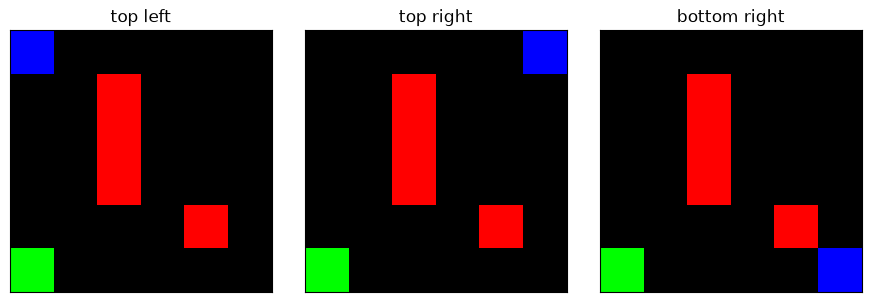

In [4]:
def render_goal_observation(state, goal):
    observation = np.zeros(
        (3, GRID_SIZE, GRID_SIZE),
        dtype=np.float32,
    )

    # Channel 0: mark only obstacle locations.
    for obstacle_row, obstacle_column in OBSTACLES:
        observation[0, obstacle_row, obstacle_column] = 1.0

    # Channel 1: mark the agent's current location.
    observation[1, state[0], state[1]] = 1.0

    # Channel 2: mark the requested goal location.
    observation[2, goal[0], goal[1]] = 1.0

    return observation

example_state = (5, 0)
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for goal_index, axis in enumerate(axes):
    observation = render_goal_observation(example_state, GOAL_STATES[goal_index])
    axis.imshow(observation.transpose(1, 2, 0))
    axis.set_title(GOAL_NAMES[goal_index])
    axis.set_xticks([]); axis.set_yticks([])
plt.tight_layout()

## 2. A goal-conditioned expert

For this known grid we can compute shortest-path distances with **breadth-first search (BFS)**. We begin at the goal and expand outward one grid step at a time. Therefore, cells discovered first are one step away, cells discovered in the next layer are two steps away, and so on.

`deque` means **double-ended queue**. Here we use it as a first-in, first-out queue: `append(...)` adds a state to the right end, while `popleft()` removes the oldest state from the left end. This ordering is what makes BFS process all states at distance $d$ before states at distance $d+1$. The expert then selects the action whose next state has the smallest recorded distance to the requested goal.

In [5]:
def shortest_path_distances(goal):
    # Start at the goal itself, which is zero moves away from the goal.
    # The dictionary also records which states BFS has already visited.
    distances = {goal: 0}

    # deque is a double-ended queue. We initially put only the goal in it.
    queue = deque([goal])

    # Continue until there are no newly discovered states left to process.
    while queue:
        # Remove the oldest queued state (first in, first out).
        state = queue.popleft()

        # Examine the neighboring state produced by every possible action.
        for action in range(len(ACTION_DELTAS)):
            neighbor = transition(state, action)

            # The first time BFS reaches a state is through a shortest path.
            if neighbor not in distances:
                distances[neighbor] = distances[state] + 1

                # Process this newly discovered state after the current layer.
                queue.append(neighbor)

    return distances

DISTANCE_MAPS = [shortest_path_distances(goal) for goal in GOAL_STATES]

In [8]:
len(DISTANCE_MAPS[0]), len(DISTANCE_MAPS[1]), len(DISTANCE_MAPS[2])

(32, 32, 32)

### Exercise 2 — Select the expert action

Evaluate all four next states with the distance map and return the index of the minimum. A blocked action leaves the state unchanged, so it will not improve the distance.

In [10]:
def expert_action(state, goal_index):
    distances = DISTANCE_MAPS[goal_index]
    # calculate the distance after each possible action.
    distance_values = []
    for action in range(len(ACTION_DELTAS)):
        next_state = transition(state, action)
        distance_values.append(distances.get(next_state, float('inf')))

    # return the action index with the smallest distance.
    return np.argmin(distance_values)

for goal_index, goal_name in enumerate(GOAL_NAMES):
    action = expert_action(example_state, goal_index)
    print(f"At {example_state}, goal '{goal_name}' -> {ACTION_NAMES[action]}")

At (5, 0), goal 'top left' -> up
At (5, 0), goal 'top right' -> up
At (5, 0), goal 'bottom right' -> right


## 3. Build demonstrations

We enumerate every reachable non-goal state with every goal. Each demonstration contains the current visual observation, its goal identity, and the expert action.

In [12]:
reachable_states = [
    (row, column) for row in range(GRID_SIZE) for column in range(GRID_SIZE)
    if (row, column) not in OBSTACLES
]
observations, goal_indices, action_labels, state_goal_pairs = [], [], [], []

for goal_index, goal in enumerate(GOAL_STATES):
    for state in reachable_states:
        if state == goal:
            continue
        # append the rendered observation, goal index, expert action,
        # and (state, goal_index) pair to their corresponding lists.
        observations.append(
            render_goal_observation(state, goal)
        )
        goal_indices.append(goal_index)
        action_labels.append(
            expert_action(state, goal_index)
        )
        state_goal_pairs.append(
            (state, goal_index)
        )

permutation = np.random.default_rng(SEED).permutation(len(observations))
split = int(0.8 * len(permutation))
train_indices, validation_indices = permutation[:split], permutation[split:]
observation_tensor = torch.tensor(np.stack(observations))
goal_tensor = torch.tensor(goal_indices, dtype=torch.long)
action_tensor = torch.tensor(action_labels, dtype=torch.long)
print(f"{len(train_indices)} training and {len(validation_indices)} validation demonstrations")

74 training and 19 validation demonstrations


### Inspect the dataset and split

The split is performed over complete `(state, goal)` demonstrations. The training and validation sets therefore contain different state-goal pairs, although the same agent position or the same goal may appear in both sets as part of different pairs. The validation set measures how well the model handles held-out combinations from this small grid; it is not a test on a completely new environment.

The first visualization uses one grid per goal because the split applies to `(agent state, goal)` pairs: the same agent state can belong to training for one goal and validation for another. Blue cells are training pairs, orange cells are validation pairs, dark cells are obstacles, and the star is the goal (which has no action example).

In the example inputs below, each image is the model input and its title shows the target supplied by the expert. Red marks obstacles, green marks the agent, and blue marks the requested goal.

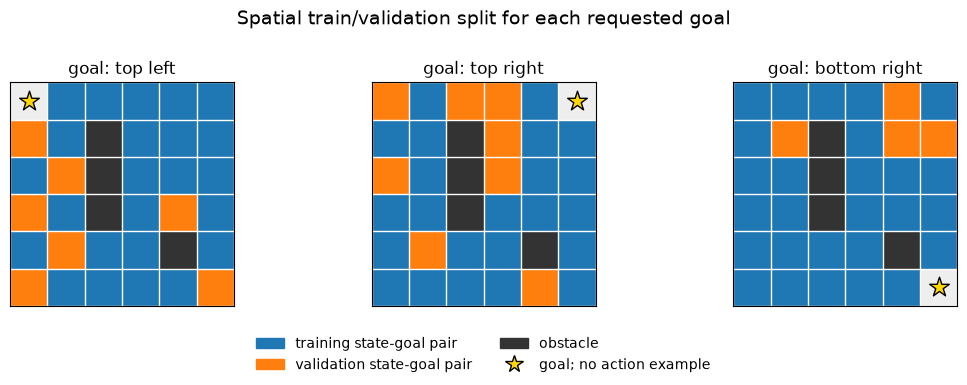

In [29]:
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

split_names = ["training", "validation"]
train_index_set = set(train_indices.tolist())
split_colormap = ListedColormap(["#eeeeee", "tab:blue", "tab:orange", "#333333"])
split_norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], split_colormap.N)

fig, axes = plt.subplots(1, len(GOAL_STATES), figsize=(11, 3.8))
for goal_index, axis in enumerate(axes):
    # Codes: 0 = goal/no example, 1 = training, 2 = validation, 3 = obstacle.
    split_map = np.zeros((GRID_SIZE, GRID_SIZE), dtype=int)
    for obstacle_row, obstacle_column in OBSTACLES:
        split_map[obstacle_row, obstacle_column] = 3

    for sample_index, (state, sample_goal_index) in enumerate(state_goal_pairs):
        if sample_goal_index == goal_index:
            row, column = state
            split_map[row, column] = 1 if sample_index in train_index_set else 2

    axis.imshow(split_map, cmap=split_colormap, norm=split_norm)
    goal_row, goal_column = GOAL_STATES[goal_index]
    axis.scatter(goal_column, goal_row, marker="*", s=220, c="gold", edgecolors="black")
    axis.set_title(f"goal: {GOAL_NAMES[goal_index]}")
    axis.set_xticks(np.arange(-0.5, GRID_SIZE, 1), minor=True)
    axis.set_yticks(np.arange(-0.5, GRID_SIZE, 1), minor=True)
    axis.grid(which="minor", color="white", linewidth=1)
    axis.tick_params(which="both", bottom=False, left=False, labelbottom=False, labelleft=False)

legend_items = [
    Patch(color="tab:blue", label="training state-goal pair"),
    Patch(color="tab:orange", label="validation state-goal pair"),
    Patch(color="#333333", label="obstacle"),
    Line2D([], [], marker="*", markersize=13, markerfacecolor="gold",
           markeredgecolor="black", linestyle="None", label="goal; no action example"),
]
fig.legend(handles=legend_items, loc="lower center", ncol=2, frameon=False)
fig.suptitle("Spatial train/validation split for each requested goal", fontsize=14)
plt.tight_layout(rect=(0, 0.16, 1, 0.92))

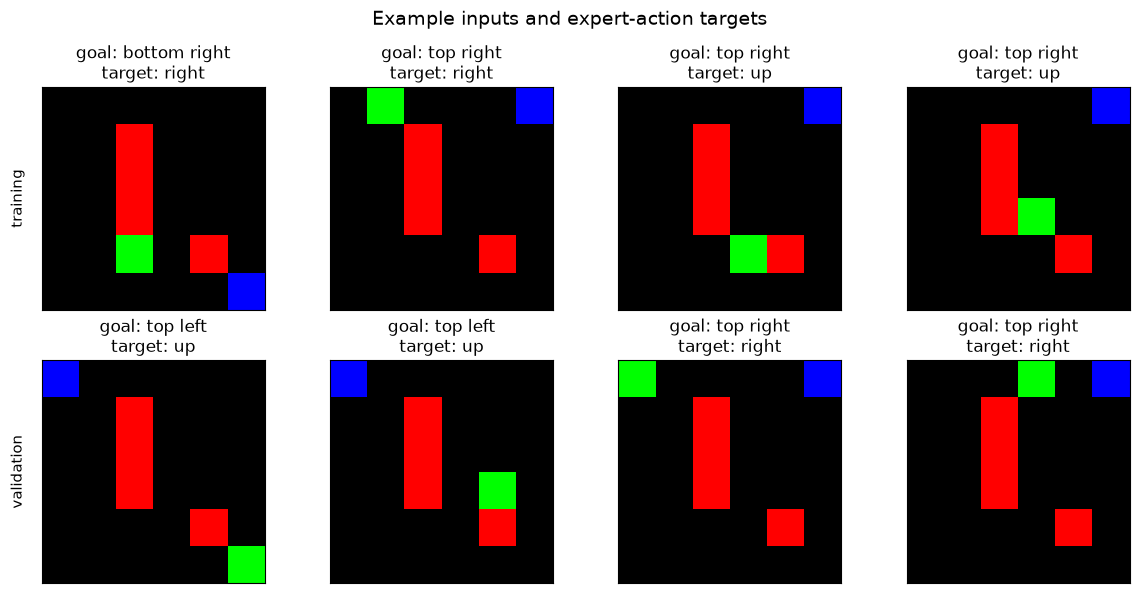

In [30]:
number_examples_per_split = 4
example_indices = [
    train_indices[:number_examples_per_split],
    validation_indices[:number_examples_per_split],
]

fig, axes = plt.subplots(2, number_examples_per_split, figsize=(12, 6))
for row, (split_name, indices) in enumerate(zip(split_names, example_indices)):
    for column, sample_index in enumerate(indices):
        goal_index = goal_indices[sample_index]
        target_action = action_labels[sample_index]
        axes[row, column].imshow(observations[sample_index].transpose(1, 2, 0))
        axes[row, column].set_title(
            f"goal: {GOAL_NAMES[goal_index]}\n"
            f"target: {ACTION_NAMES[target_action]}"
        )
        axes[row, column].set_xticks([])
        axes[row, column].set_yticks([])
    axes[row, 0].set_ylabel(split_name, fontsize=11, labelpad=12)

fig.suptitle("Example inputs and expert-action targets", fontsize=14)
plt.tight_layout()

## 4. Learn from a visual goal

The CNN receives the obstacle, agent, and goal channels together. The goal is therefore spatial: the policy can use where the desired destination lies relative to the agent. From this image-like tensor, the model must select one of four action classes: up, right, down, or left.

We assign semantic meanings to the three channels when constructing the data, but the model itself only receives numbers. It is not explicitly told what an agent, obstacle, or goal is. By learning from expert input-action pairs, it discovers numerical spatial patterns that are useful for predicting each action. This deliberately structured representation avoids the harder perception problem of recognizing those concepts in ordinary camera pixels, letting us focus on goal-conditioned policy learning.

In [16]:
class VisualGoalPolicy(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 24, 3, padding=1), nn.ReLU(),
            nn.Conv2d(24, 32, 3, padding=1), nn.ReLU(),
            nn.Flatten(),
        )
        self.classifier = nn.Sequential(nn.Linear(32 * GRID_SIZE * GRID_SIZE, 64), nn.ReLU(), nn.Linear(64, 4))

    def forward(self, observation):
        # encode the observation and classify the action.
        encoded = self.encoder(observation)
        return self.classifier(encoded)

visual_policy = VisualGoalPolicy().to(DEVICE)
optimizer = torch.optim.Adam(visual_policy.parameters(), lr=3e-3)
train_x = observation_tensor[train_indices].to(DEVICE)
train_y = action_tensor[train_indices].to(DEVICE)
for epoch in range(150):
    optimizer.zero_grad()
    loss = nn.functional.cross_entropy(visual_policy(train_x), train_y)
    loss.backward(); optimizer.step()
print(f"final training loss: {loss.item():.4f}")

final training loss: 0.0001


## 5. Offline accuracy and closed-loop success

Classification accuracy asks whether one predicted action matches the expert on each held-out validation example. It is an **offline, one-step** metric: the predicted action is compared with the stored target, but the agent does not move.

Closed-loop evaluation repeatedly lets the policy observe, act, and receive the resulting next observation. A rollout is successful if the agent reaches its requested goal within `maximum_steps=30`. Thirty steps is a generous horizon for this $6\times6$ grid, whose useful shortest paths are much shorter, while still guaranteeing that evaluation terminates. If a policy repeatedly selects a blocked action, cycles between states, or follows an unnecessarily long route, the rollout stops after 30 actions and counts as a failure.

Closed-loop success is therefore stricter: every prediction changes the input to the next prediction, so errors can accumulate. However, an action that differs from the expert label need not cause failure because another route may still reach the same goal. Here, one-step accuracy is measured only on validation demonstrations, while the final closed-loop evaluation starts from every available state-goal pair in the small grid.

In [31]:
@torch.no_grad()
def visual_policy_action(model, state, goal):
    observation = torch.tensor(render_goal_observation(state, goal))[None].to(DEVICE)
    return int(model(observation).argmax(dim=1).item())

def rollout_visual_policy(model, start, goal, maximum_steps=30):
    state, trajectory = start, [start]
    for _ in range(maximum_steps):
        if state == goal:
            break
        # predict an action, apply transition, and append the new state.
        action = visual_policy_action(model, state, goal)
        state = transition(state, action)
        trajectory.append(state)
    return trajectory, state == goal

visual_policy.eval()
with torch.no_grad():
    validation_logits = visual_policy(observation_tensor[validation_indices].to(DEVICE))
    validation_accuracy = (validation_logits.argmax(1).cpu() == action_tensor[validation_indices]).float().mean().item()
results = [rollout_visual_policy(visual_policy, state, GOAL_STATES[g])[1] for state, g in state_goal_pairs]
print(f"validation action accuracy: {validation_accuracy:.3f}")
print(f"closed-loop success: {np.mean(results):.3f}")

validation action accuracy: 0.842
closed-loop success: 0.817


### Inspect prediction and rollout failures

A scalar accuracy hides which spatial situations are difficult. The first diagnostic samples validation inputs for which the model's action differs from the expert label. Remember that a mismatch is not necessarily a useless action: the expert stores one shortest-path choice, while another action might still lead to the goal.

The second diagnostic selects up to three representative failed rollouts, preferring different requested goals when such failures are available. In each row, the left panel draws the predicted path and the right panel counts how often each state was visited. Repeated visits expose a loop or a policy that remains stuck by repeatedly choosing a blocked action. Because a rollout contains the initial state plus up to 30 resulting states, a failed trajectory may contain 31 recorded positions.

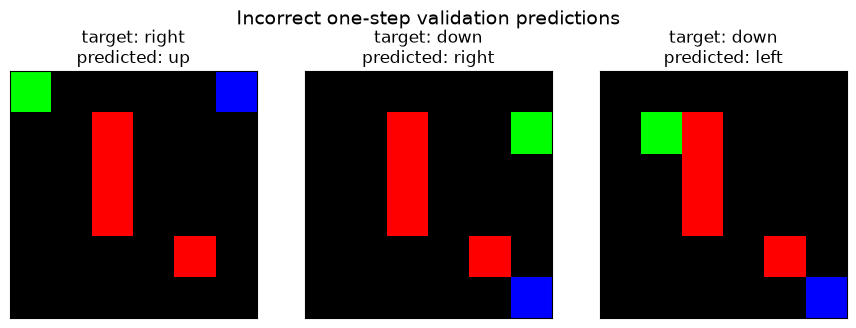

In [32]:
validation_predictions = validation_logits.argmax(dim=1).cpu()
validation_targets = action_tensor[validation_indices]
wrong_local_indices = torch.nonzero(
    validation_predictions != validation_targets, as_tuple=False
).squeeze(1).numpy()

if len(wrong_local_indices) == 0:
    print("No incorrect validation predictions to visualize.")
else:
    number_to_show = min(4, len(wrong_local_indices))
    rng = np.random.default_rng(SEED)
    selected_local_indices = rng.choice(
        wrong_local_indices, size=number_to_show, replace=False
    )

    fig, axes = plt.subplots(1, number_to_show, figsize=(3 * number_to_show, 3.3))
    axes = np.atleast_1d(axes)
    for axis, local_index in zip(axes, selected_local_indices):
        sample_index = int(validation_indices[local_index])
        target = int(validation_targets[local_index])
        prediction = int(validation_predictions[local_index])
        axis.imshow(observations[sample_index].transpose(1, 2, 0))
        axis.set_title(
            f"target: {ACTION_NAMES[target]}\n"
            f"predicted: {ACTION_NAMES[prediction]}"
        )
        axis.set_xticks([])
        axis.set_yticks([])
    fig.suptitle("Incorrect one-step validation predictions", fontsize=14)
    plt.tight_layout()

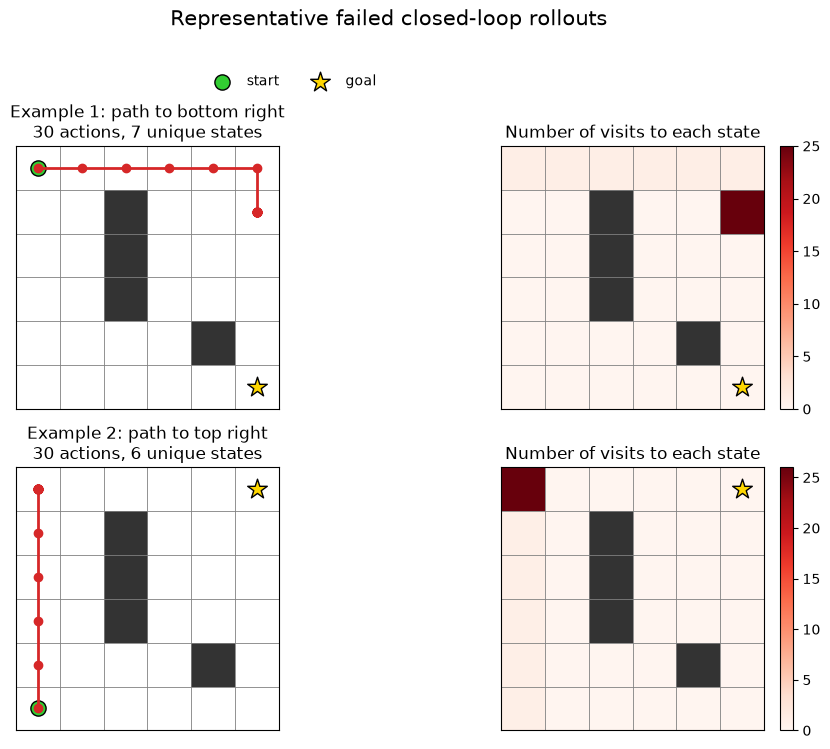

In [36]:
DISPLAY_COUNT = 2
failed_rollouts = []
for start, goal_index in state_goal_pairs:
    trajectory, succeeded = rollout_visual_policy(
        visual_policy, start, GOAL_STATES[goal_index]
    )
    if not succeeded:
        failed_rollouts.append((start, goal_index, trajectory))

if not failed_rollouts:
    print("No failed closed-loop rollout to visualize.")
else:
    # Rank moving failures ahead of failures that stayed in one cell.
    ranked_failures = sorted(
        failed_rollouts, key=lambda item: len(set(item[2])), reverse=True
    )

    # Prefer different requested goals when possible, then fill any remaining
    # rows with the next most informative failures.
    selected_failures = []
    selected_goals = set()
    for failure in ranked_failures:
        if failure[1] not in selected_goals:
            selected_failures.append(failure)
            selected_goals.add(failure[1])
        if len(selected_failures) == DISPLAY_COUNT:
            break
    for failure in ranked_failures:
        if len(selected_failures) == DISPLAY_COUNT:
            break
        if failure not in selected_failures:
            selected_failures.append(failure)

    obstacle_map = np.zeros((GRID_SIZE, GRID_SIZE), dtype=int)
    for obstacle_row, obstacle_column in OBSTACLES:
        obstacle_map[obstacle_row, obstacle_column] = 1

    number_examples = len(selected_failures)
    fig, axes = plt.subplots(
        number_examples, 2, figsize=(9, 3.8 * number_examples), squeeze=False
    )

    for example_index, (start, goal_index, trajectory) in enumerate(selected_failures):
        goal = GOAL_STATES[goal_index]
        rows = [state[0] for state in trajectory]
        columns = [state[1] for state in trajectory]

        visit_counts = np.zeros((GRID_SIZE, GRID_SIZE), dtype=float)
        for row, column in trajectory:
            visit_counts[row, column] += 1
        for obstacle_row, obstacle_column in OBSTACLES:
            visit_counts[obstacle_row, obstacle_column] = np.nan

        path_axis, count_axis = axes[example_index]
        path_axis.imshow(
            obstacle_map, cmap=ListedColormap(["white", "#333333"])
        )
        path_axis.plot(columns, rows, color="tab:red", marker="o", linewidth=2)
        path_axis.scatter(
            start[1], start[0], c="limegreen", s=120, edgecolors="black", label="start"
        )
        path_axis.scatter(
            goal[1], goal[0], c="gold", marker="*", s=220,
            edgecolors="black", label="goal"
        )
        path_axis.set_title(
            f"Example {example_index + 1}: path to {GOAL_NAMES[goal_index]}\n"
            f"{len(trajectory) - 1} actions, {len(set(trajectory))} unique states"
        )

        visit_colormap = plt.colormaps["Reds"].copy()
        visit_colormap.set_bad("#333333")
        image = count_axis.imshow(visit_counts, cmap=visit_colormap, vmin=0)
        count_axis.scatter(
            goal[1], goal[0], c="gold", marker="*", s=220, edgecolors="black"
        )
        count_axis.set_title("Number of visits to each state")
        fig.colorbar(image, ax=count_axis, fraction=0.046, pad=0.04)

        for axis in (path_axis, count_axis):
            axis.set_xticks(np.arange(-0.5, GRID_SIZE, 1), minor=True)
            axis.set_yticks(np.arange(-0.5, GRID_SIZE, 1), minor=True)
            axis.grid(which="minor", color="gray", linewidth=0.6)
            axis.tick_params(
                which="both", bottom=False, left=False,
                labelbottom=False, labelleft=False
            )

    axes[0, 0].legend(
        loc="upper center", bbox_to_anchor=(1.05, 1.32),
        ncol=2, frameon=False
    )
    fig.suptitle("Representative failed closed-loop rollouts", fontsize=15)
    plt.tight_layout(rect=(0, 0, 1, 0.97))

## 6. Replace the goal image with language

Now the visual input contains only obstacles and the agent. A learned embedding represents the instruction *top left*, *top right*, or *bottom right*. Concatenating visual and instruction features lets the action head condition its decision on both. This is a tiny analogy to a vision-language-action pipeline—not a language model.

In [38]:
class TinyVisionLanguageActionPolicy(nn.Module):
    def __init__(self, number_instructions=3, embedding_dimension=12):
        super().__init__()
        self.visual_encoder = nn.Sequential(
            nn.Conv2d(2, 24, 3, padding=1), nn.ReLU(),
            nn.Conv2d(24, 32, 3, padding=1), nn.ReLU(), nn.Flatten(),
            nn.Linear(32 * GRID_SIZE * GRID_SIZE, 64), nn.ReLU(),
        )
        self.instruction_embedding = nn.Embedding(number_instructions, embedding_dimension)
        self.action_head = nn.Sequential(nn.Linear(64 + embedding_dimension, 64), nn.ReLU(), nn.Linear(64, 4))

    def forward(self, visual_observation, instruction_ids):
        # encode vision and instruction, concatenate them on the feature
        # dimension, and return action logits from the action head.
        visual_features = self.visual_encoder(visual_observation)
        instruction_features = self.instruction_embedding(instruction_ids)
        combined_features = torch.cat((visual_features, instruction_features), dim=1)
        return self.action_head(combined_features)

vla_policy = TinyVisionLanguageActionPolicy().to(DEVICE)
vla_optimizer = torch.optim.Adam(vla_policy.parameters(), lr=3e-3)
vla_train_x = observation_tensor[train_indices, :2].to(DEVICE)
vla_train_goals = goal_tensor[train_indices].to(DEVICE)
for epoch in range(150):
    vla_optimizer.zero_grad()
    vla_loss = nn.functional.cross_entropy(vla_policy(vla_train_x, vla_train_goals), train_y)
    vla_loss.backward(); vla_optimizer.step()
print(f"final VLA training loss: {vla_loss.item():.4f}")

final VLA training loss: 0.0010


### Exercise 7 — Test instruction conditioning

Complete the action helper and rollout. Then inspect the same visual scene under all three instructions: different outputs demonstrate conditioning, not three different observations.

In [40]:
@torch.no_grad()
def vla_policy_action(model, state, instruction_id):
    visual = torch.tensor(render_goal_observation(state, GOAL_STATES[instruction_id])[:2])[None].to(DEVICE)
    instruction = torch.tensor([instruction_id], device=DEVICE)
    # return the action index with the largest logit.
    logits = model(visual, instruction)
    return int(logits.argmax(dim=1).item())

def rollout_vla_policy(model, start, instruction_id, maximum_steps=30):
    goal, state, trajectory = GOAL_STATES[instruction_id], start, [start]
    for _ in range(maximum_steps):
        if state == goal:
            break
        action = vla_policy_action(model, state, instruction_id)
        state = transition(state, action)
        trajectory.append(state)
    return trajectory, state == goal

vla_policy.eval()
for instruction_id, name in enumerate(GOAL_NAMES):
    action = vla_policy_action(vla_policy, example_state, instruction_id)
    print(f"same scene + '{name}' -> {ACTION_NAMES[action]}")
vla_results = [rollout_vla_policy(vla_policy, state, g)[1] for state, g in state_goal_pairs]
print(f"closed-loop VLA success: {np.mean(vla_results):.3f}")

same scene + 'top left' -> up
same scene + 'top right' -> up
same scene + 'bottom right' -> right
closed-loop VLA success: 1.000


### Visualize the complete learned action fields

Each panel fixes one instruction and queries the learned policy at every reachable non-goal agent state. An arrow shows the action with the largest predicted logit. Blue arrows match the particular shortest-path action stored by our expert; orange arrows differ from that label, although they may still begin another successful route. An arrow pointing into a wall, obstacle, or grid boundary would leave the agent in the same state.

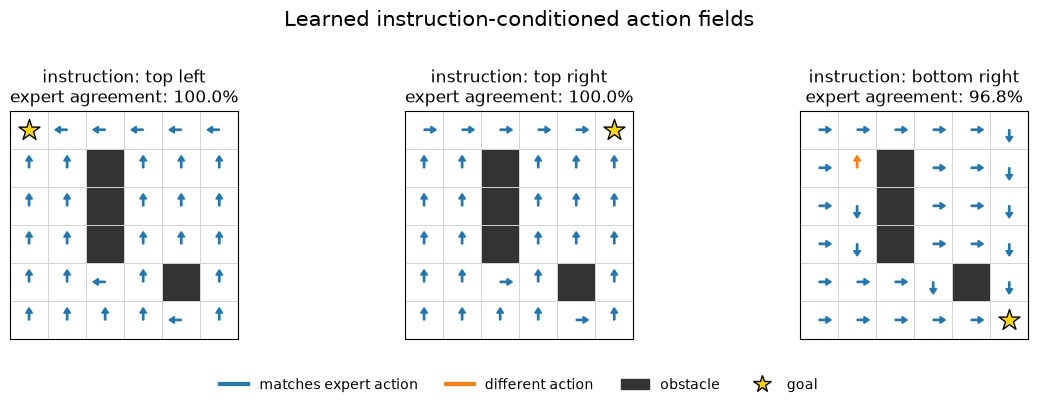

In [41]:
fig, axes = plt.subplots(1, len(GOAL_STATES), figsize=(12, 4))
obstacle_map = np.zeros((GRID_SIZE, GRID_SIZE), dtype=int)
for obstacle_row, obstacle_column in OBSTACLES:
    obstacle_map[obstacle_row, obstacle_column] = 1

for instruction_id, axis in enumerate(axes):
    goal = GOAL_STATES[instruction_id]
    axis.imshow(
        obstacle_map, cmap=ListedColormap(["white", "#333333"]),
        vmin=0, vmax=1
    )

    number_matches = 0
    number_states = 0
    for state in reachable_states:
        if state == goal:
            continue
        predicted_action = vla_policy_action(vla_policy, state, instruction_id)
        target_action = expert_action(state, instruction_id)
        matches_expert = predicted_action == target_action
        number_matches += int(matches_expert)
        number_states += 1

        row, column = state
        delta_row, delta_column = ACTION_DELTAS[predicted_action]
        axis.arrow(
            column, row, 0.32 * delta_column, 0.32 * delta_row,
            width=0.035, head_width=0.18, head_length=0.14,
            length_includes_head=True,
            color="tab:blue" if matches_expert else "tab:orange",
        )

    goal_row, goal_column = goal
    axis.scatter(
        goal_column, goal_row, marker="*", s=250, c="gold",
        edgecolors="black", zorder=3
    )
    axis.set_title(
        f"instruction: {GOAL_NAMES[instruction_id]}\n"
        f"expert agreement: {number_matches / number_states:.1%}"
    )
    axis.set_xticks(np.arange(-0.5, GRID_SIZE, 1), minor=True)
    axis.set_yticks(np.arange(-0.5, GRID_SIZE, 1), minor=True)
    axis.grid(which="minor", color="lightgray", linewidth=0.7)
    axis.tick_params(
        which="both", bottom=False, left=False,
        labelbottom=False, labelleft=False
    )

field_legend = [
    Line2D([], [], color="tab:blue", linewidth=3, label="matches expert action"),
    Line2D([], [], color="tab:orange", linewidth=3, label="different action"),
    Patch(color="#333333", label="obstacle"),
    Line2D([], [], marker="*", markersize=13, markerfacecolor="gold",
           markeredgecolor="black", linestyle="None", label="goal"),
]
fig.legend(handles=field_legend, loc="lower center", ncol=4, frameon=False)
fig.suptitle("Learned instruction-conditioned action fields", fontsize=15)
plt.tight_layout(rect=(0, 0.12, 1, 0.92))

## 7. From the toy model to VLA systems

Our model follows the abstract pattern **vision + instruction → action**, but real VLA systems are far richer. They may use a pretrained vision-language backbone, tokenize continuous robot actions, train across many tasks and robot datasets, and predict a short action sequence rather than one grid move.

The important conceptual bridge is conditioning: the instruction changes which behavior is appropriate without changing the current scene. Pretraining can provide broad visual and semantic knowledge, while robot demonstrations connect those representations to actions. It does not automatically solve embodiment, control precision, safety, or distribution shift.

## 8. Reflection

1. Why is the current image insufficient when the environment supports several goals?

   *Your answer.*

2. What is the difference between a visual goal channel and an instruction embedding?

   *Your answer.*

3. Why can one-step action accuracy overestimate practical policy quality?

   *Your answer.*

4. In what sense is the second model VLA-like, and in what sense is it not a real VLA model?

   *Your answer.*

5. What can vision-language pretraining contribute to robot learning, and what problems remain?

   *Your answer.*